<a href="https://colab.research.google.com/github/Wakenc89/El_bariete/blob/main/Copia_de_h4_1_kmeans_anemia_infantil_comentado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# H4_1 — K-Means: Segmentación de Niños con Anemia Infantil en Bolivia (0 a 7 años)

**Universidad Franz Tamayo — Minería de Datos**
**Carrera:** Ingeniería de Sistemas | **Autor:** Diego | **Docente:** Enrique Alejandro Laurel Cossio | **2026**

---

## Objetivo

Aplicar el algoritmo **K-Means** (aprendizaje no supervisado) a la base de datos de **anemia infantil en Bolivia** para descubrir **grupos de niños con características parecidas** (edad, peso, talla y hemoglobina) **sin decirle al algoritmo quién tiene anemia**. Después comprobamos si los grupos encontrados tienen sentido clínico.

## ¿Cómo funciona K-Means? (resumen)

1. Se elige el número de grupos **K**.
2. Se ubican K centros (centroides) al azar.
3. Cada niño se asigna al centro más cercano (distancia euclidiana).
4. Cada centro se mueve al promedio de los niños de su grupo.
5. Se repiten los pasos 3 y 4 hasta que los centros ya no cambian.

> El algoritmo busca minimizar el **WCSS** (suma de distancias al cuadrado de cada niño a su centroide). Menor WCSS = grupos más compactos.

---
## 1. Librerías
**¿Qué herramientas necesitamos?**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


**Qué significa:** las librerías se cargaron sin errores. `pandas` y `numpy` manejan los datos, `matplotlib` y `seaborn` hacen los gráficos, y de `scikit-learn` usamos `KMeans` (el algoritmo), `StandardScaler` (para escalar) y `silhouette_score` (para medir la calidad de los grupos).

---
## 2. Carga de los datos
**¿Cuántos niños tenemos y qué información hay de cada uno?**

In [ ]:
# El Excel tiene un título en la fila 1 y una fila vacía, por eso el encabezado real está en la fila 4 (header=3)
df = pd.read_excel("anemia_infantil_datos.xlsx", header=3)

print(f"Filas    : {df.shape[0]:,}")
print(f"Columnas : {df.shape[1]}")
df.head()

Filas    : 10,500
Columnas : 15


,ID_Registro,Departamento,Área,Edad_Meses,Grupo_Etario,Sexo,Peso_kg,Talla_cm,Hemoglobina_g_dL,Grado_Anemia,Consume_Suplemento_Hierro,Lactancia_Materna_Exclusiva,Nivel_Educativo_Madre,Deteccion_Tardia_Anemia,Fecha_Tamizaje
0,BOL-000001,Santa Cruz,Urbana,51,24-59 meses (preescolar),Masculino,15.7,87.4,8.3,Moderada,Sí,No aplica,Secundaria,Sí,2024-03-07
1,BOL-000002,Cochabamba,Rural,14,12-23 meses (lactante mayor),Femenino,6.3,65.9,13.5,Sin anemia,No,No aplica,Secundaria,No,2025-07-13
2,BOL-000003,La Paz,Urbana,71,60-83 meses (escolar 5-7 años),Femenino,19.4,99.6,13.8,Sin anemia,No,No aplica,Secundaria,No,2025-12-20
3,BOL-000004,Cochabamba,Rural,60,60-83 meses (escolar 5-7 años),Femenino,16.1,86.8,8.4,Moderada,Sí,No aplica,Secundaria,No,2024-08-14
4,BOL-000005,Tarija,Urbana,20,12-23 meses (lactante mayor),Masculino,7.3,71.6,10.8,Leve,Sí,No aplica,Secundaria,No,2026-04-18


**Qué significa:** la base tiene **10,500 niños** de 0 a 7 años (0 a 83 meses) y **15 columnas**: departamento, área, edad, peso, talla, hemoglobina, grado de anemia, suplemento de hierro, educación de la madre, etc. Cada fila es un niño tamizado en Bolivia.

**¿Hay datos faltantes o duplicados?**

In [ ]:
df.info()
print()
print("Valores nulos por columna:")
print(df.isnull().sum())
print("\nRegistros duplicados (ID_Registro):", df['ID_Registro'].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10500 entries, 0 to 10499
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID_Registro                  10500 non-null  str    
 1   Departamento                 10500 non-null  str    
 2   Área                         10500 non-null  str    
 3   Edad_Meses                   10500 non-null  int64  
 4   Grupo_Etario                 10500 non-null  str    
 5   Sexo                         10500 non-null  str    
 6   Peso_kg                      10500 non-null  float64
 7   Talla_cm                     10500 non-null  float64
 8   Hemoglobina_g_dL             10500 non-null  float64
 9   Grado_Anemia                 10500 non-null  str    
 10  Consume_Suplemento_Hierro    10500 non-null  str    
 11  Lactancia_Materna_Exclusiva  10500 non-null  str    
 12  Nivel_Educativo_Madre        10500 non-null  str    
 13  Deteccion_Tardia_Anemia    

**Qué significa:** no hay valores nulos ni registros duplicados, así que los datos llegaron limpios y no hace falta eliminar ni rellenar nada antes de aplicar K-Means.

---
## 3. Exploración de los datos
**¿Cómo son las variables numéricas de los niños?**

In [ ]:
df[['Edad_Meses', 'Peso_kg', 'Talla_cm', 'Hemoglobina_g_dL']].describe().round(2)

,Edad_Meses,Peso_kg,Talla_cm,Hemoglobina_g_dL
count,10500.00,10500.00,10500.00,10500.00
mean,41.49,13.32,82.95,11.45
std,24.18,5.26,16.23,2.48
min,0.00,2.60,45.00,4.50
25%,20.00,7.88,71.30,10.30
50%,41.00,14.70,84.50,11.70
75%,62.00,17.40,96.00,13.30
max,83.00,25.60,120.00,15.80


**Qué significa:** el niño promedio tiene unos **41 meses** (3.5 años), pesa **13.3 kg**, mide **83 cm** y tiene hemoglobina de **11.45 g/dL**. La hemoglobina va de 4.5 a 15.8 g/dL; el valor mínimo (4.5) corresponde a casos muy graves. Las variables tienen escalas muy distintas (la talla llega a 120 y la hemoglobina a 15.8), lo que obliga a escalarlas más adelante.

**¿Cómo se distribuyen la edad, el peso, la talla y la hemoglobina?**

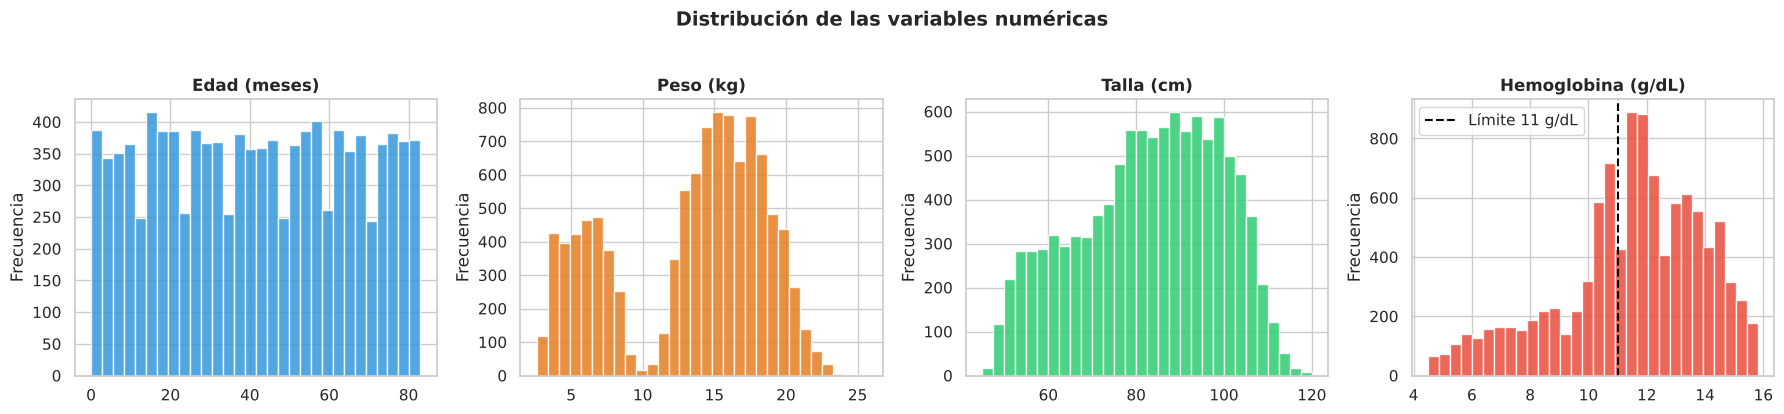

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
vars_num = [('Edad_Meses', 'Edad (meses)', '#3498db'),
            ('Peso_kg', 'Peso (kg)', '#e67e22'),
            ('Talla_cm', 'Talla (cm)', '#2ecc71'),
            ('Hemoglobina_g_dL', 'Hemoglobina (g/dL)', '#e74c3c')]

for ax, (col, etiqueta, color) in zip(axes, vars_num):
    ax.hist(df[col], bins=30, color=color, edgecolor='white', alpha=0.85)
    ax.set_title(etiqueta, fontweight='bold')
    ax.set_ylabel('Frecuencia')

# Línea de referencia clínica: Hb < 11 g/dL indica anemia en menores de 5 años
axes[3].axvline(11, color='black', linestyle='--', label='Límite 11 g/dL')
axes[3].legend()

plt.suptitle('Distribución de las variables numéricas', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Qué significa:** la **edad** está repartida de forma pareja entre 0 y 83 meses (hay una cantidad similar de niños de cada edad). El **peso** forma dos bloques: uno de niños pequeños (menos de 10 kg, los lactantes) y otro de niños mayores (12 a 22 kg). La **talla** crece de forma continua. La **hemoglobina** se concentra entre 11 y 14 g/dL, pero tiene una cola larga hacia la izquierda que llega hasta 4.5 g/dL; los niños a la izquierda de la línea punteada (11 g/dL, límite clínico) tienen anemia, y son una parte importante de la población.

**¿Qué variables están relacionadas entre sí?**

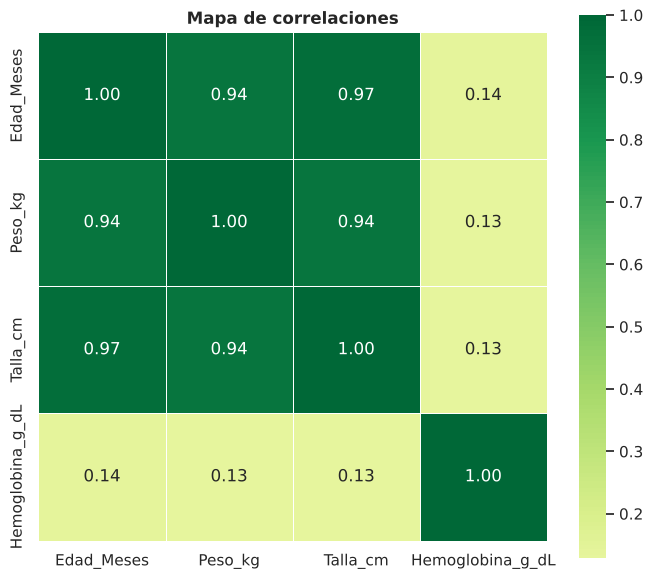

In [ ]:
vars_num = ['Edad_Meses', 'Peso_kg', 'Talla_cm', 'Hemoglobina_g_dL']

plt.figure(figsize=(7, 6))
sns.heatmap(df[vars_num].corr(), annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, square=True, linewidths=0.5)
plt.title('Mapa de correlaciones', fontweight='bold')
plt.tight_layout()
plt.show()

**Qué significa:** edad, peso y talla están **muy correlacionadas** (entre 0.94 y 0.97): mientras más crece el niño, más pesa y más mide. En cambio, la hemoglobina casi no se relaciona con ellas (correlación ≈ 0.13 a 0.14), es decir, aporta información distinta. Por eso el modelo va a separar a los niños por **etapa de crecimiento** y por **nivel de hemoglobina**.

**¿Se ven grupos naturales antes de aplicar K-Means?**

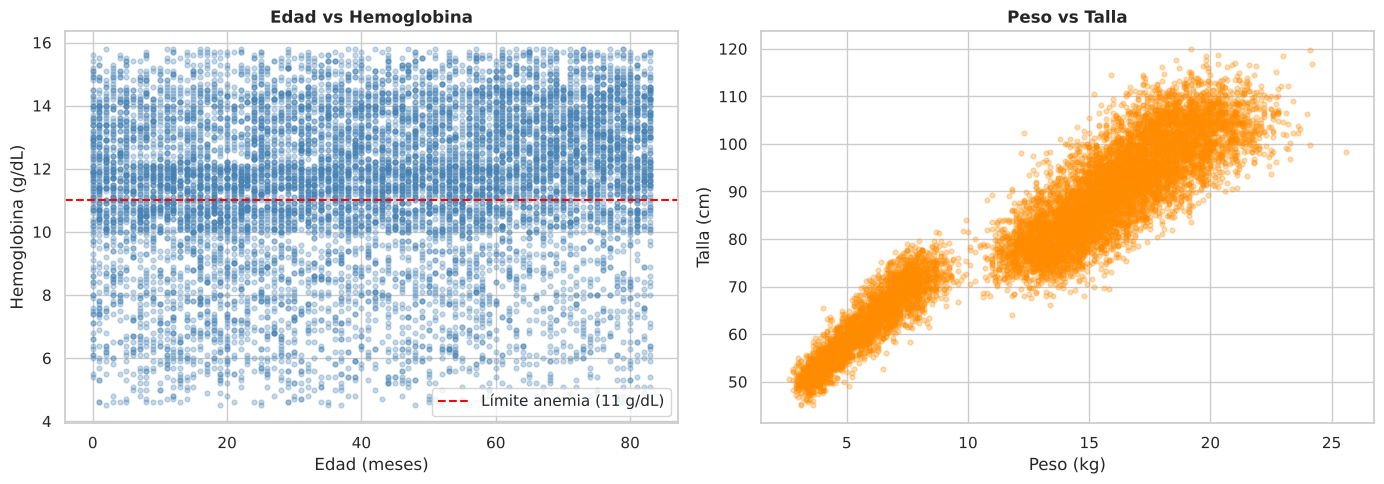

In [ ]:
# Sin colorear por cluster todavía: solo miramos si se ven grupos naturales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['Edad_Meses'], df['Hemoglobina_g_dL'], alpha=0.3, s=12, color='steelblue')
axes[0].axhline(11, color='red', linestyle='--', label='Límite anemia (11 g/dL)')
axes[0].set_xlabel('Edad (meses)'); axes[0].set_ylabel('Hemoglobina (g/dL)')
axes[0].set_title('Edad vs Hemoglobina', fontweight='bold'); axes[0].legend()

axes[1].scatter(df['Peso_kg'], df['Talla_cm'], alpha=0.3, s=12, color='darkorange')
axes[1].set_xlabel('Peso (kg)'); axes[1].set_ylabel('Talla (cm)')
axes[1].set_title('Peso vs Talla', fontweight='bold')

plt.tight_layout()
plt.show()

**Qué significa:** en *Peso vs Talla* los niños siguen una tendencia creciente (más peso, más talla) y se ven **dos nubes**: los niños pequeños abajo a la izquierda y los mayores arriba a la derecha, con muy pocos casos en medio. En *Edad vs Hemoglobina* hay niños de **todas las edades** por debajo de la línea de 11 g/dL, así que la anemia no depende solo de la edad. Esto anticipa que K-Means separará grupos combinando la etapa de crecimiento y el nivel de hemoglobina.

---
## 4. Preprocesamiento
**¿Qué variables usamos y por qué hay que escalarlas?**

Usamos **Edad, Peso, Talla y Hemoglobina**. No usamos `Grado_Anemia` porque es la respuesta que luego queremos comparar (K-Means debe agrupar sin conocerla). Como K-Means usa distancias, una variable con valores grandes (talla ≈ 80) dominaría sobre una pequeña (hemoglobina ≈ 11), así que aplicamos `StandardScaler`.

In [ ]:
# Variables que usará K-Means (solo numéricas, porque K-Means mide distancias)
features = ['Edad_Meses', 'Peso_kg', 'Talla_cm', 'Hemoglobina_g_dL']

X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("ANTES del escalado (valores originales):")
print(X.describe().loc[['mean', 'std']].round(2).to_string())
print()
print("DESPUÉS del escalado (StandardScaler):")
print(X_scaled_df.describe().loc[['mean', 'std']].round(2).to_string())

ANTES del escalado (valores originales):
      Edad_Meses  Peso_kg  Talla_cm  Hemoglobina_g_dL
mean       41.49    13.32     82.95             11.45
std        24.18     5.26     16.23              2.48

DESPUÉS del escalado (StandardScaler):
      Edad_Meses  Peso_kg  Talla_cm  Hemoglobina_g_dL
mean         0.0      0.0       0.0               0.0
std          1.0      1.0       1.0               1.0


**Qué significa:** antes del escalado cada variable tenía media y desviación muy distintas. Después, todas tienen **media = 0 y desviación = 1**, así que las cuatro pesan lo mismo en el cálculo de distancias.

---
## 5. ¿Cuántos grupos (K) elegimos?
### 5.1 Método del Codo

K=2: WCSS = 19,519
K=3: WCSS = 14,078
K=4: WCSS = 10,487


K=5: WCSS = 8,476


K=6: WCSS = 7,456
K=7: WCSS = 6,620


K=8: WCSS = 5,937
K=9: WCSS = 5,264


K=10: WCSS = 4,681


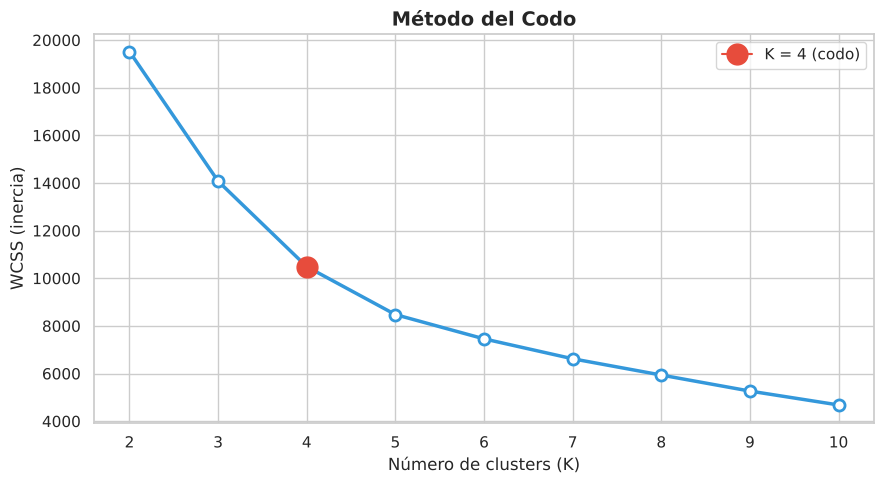

In [ ]:
# ==============================================================================
# 🧠 COMENTARIO DEL ANALISTA: ENTENDIENDO EL WCSS (INERCIA)
# ==============================================================================
# El WCSS (Suma de Cuadrados Dentro del Cluster) nos dice qué tan "apretados" o
# compactos son nuestros grupos. Matemáticamente, mide la distancia de cada niño
# al centro de su propio grupo. ¡Queremos que esa distancia sea lo más pequeña posible!
#
# Sin embargo, hay una trampa: si hacemos tantos grupos como niños en la base,
# el WCSS sería 0, pero el modelo no serviría para nada. Por eso buscamos el
# famoso "codo": el punto donde añadir un grupo adicional ya no reduce drásticamente
# el WCSS. Es nuestro punto de equilibrio ideal entre compacidad y simplicidad.
# ==============================================================================

k_range = range(2, 11)
wcss = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
    print(f"K={k}: WCSS = {km.inertia_:,.0f}")

plt.figure(figsize=(9, 5))
plt.plot(list(k_range), wcss, marker='o', linewidth=2.5, color='#3498db',
         markerfacecolor='white', markeredgewidth=2, markersize=8)
plt.plot(4, wcss[2], marker='o', markersize=15, color='#e74c3c', label='K = 4 (codo)')
plt.title('Método del Codo', fontsize=14, fontweight='bold')
plt.xlabel('Número de clusters (K)')
plt.ylabel('WCSS (inercia)')
plt.xticks(list(k_range))
plt.legend()
plt.tight_layout()
plt.show()

**Qué significa:** el WCSS siempre baja al aumentar K, pero lo importante es dónde deja de bajar rápido. De K=2 a K=4 la caída es grande (19,519 → 10,487) y desde K=4 la mejora se vuelve más lenta. Ese punto de quiebre (el "codo") sugiere **K = 4**.

### 5.2 Silhouette Score

K=2: Silhouette = 0.4507


K=3: Silhouette = 0.3671


K=4: Silhouette = 0.3926


K=5: Silhouette = 0.3820


K=6: Silhouette = 0.3559


K=7: Silhouette = 0.3229


K=8: Silhouette = 0.3291


K=9: Silhouette = 0.3179


K=10: Silhouette = 0.3152


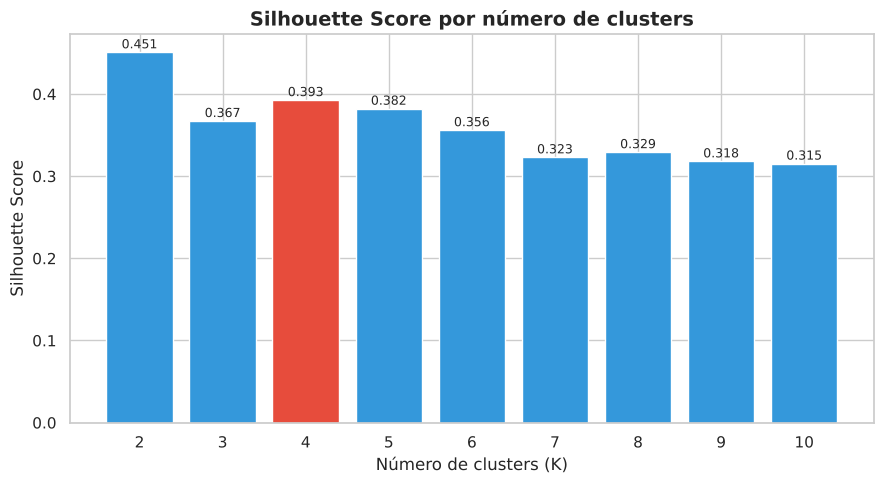

In [ ]:
# ==============================================================================
# 🧠 COMENTARIO DEL ANALISTA: ENTENDIENDO EL SILHOUETTE SCORE
# ==============================================================================
# Mientras que el WCSS solo mira hacia "adentro" de cada grupo, el coeficiente
# de Silhouette (Silueta) es un evaluador más estricto. Examina dos cosas a la vez:
# 1. Cohesión: ¿Qué tan cerca está un niño de los demás en su mismo grupo?
# 2. Separación: ¿Qué tan lejos está ese niño del grupo vecino más cercano?
#
# Un valor cerca de +1 significa grupos perfectamente separados. Un valor cerca
# de 0 significa que los niños están en la frontera (zona gris) entre dos grupos.
# Como el crecimiento humano (edad, peso, talla) es un proceso continuo, no podemos
# esperar un 1 perfecto; los grupos inevitablemente se van a rozar en las fronteras.
# ==============================================================================

silhouette_scores = []

for k in k_range:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    # Con una muestra de 5,000 puntos para que el cálculo sea rápido
    s = silhouette_score(X_scaled, labels, sample_size=5000, random_state=42)
    silhouette_scores.append(s)
    print(f"K={k}: Silhouette = {s:.4f}")

plt.figure(figsize=(9, 5))
colores = ['#e74c3c' if k == 4 else '#3498db' for k in k_range]
barras = plt.bar(list(k_range), silhouette_scores, color=colores, edgecolor='white')
for b, s in zip(barras, silhouette_scores):
    plt.text(b.get_x() + b.get_width()/2, s + 0.005, f'{s:.3f}', ha='center', fontsize=9)
plt.title('Silhouette Score por número de clusters', fontsize=14, fontweight='bold')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

**Qué significa:** el Silhouette mide qué tan separados están los grupos (más cercano a 1 es mejor). El valor más alto es en K=2 (0.451), pero solo separaría a los niños en dos grandes grupos, algo poco útil para salud. **K = 4 (0.393)** es el mejor valor después de K=2 y supera a K=3 y K=5, además coincide con el codo. Elegimos **K = 4**.

---
## 6. Entrenamiento del modelo K-Means (K = 4)
**¿Cuántos niños quedan en cada grupo?**

In [ ]:
K_OPTIMO = 4

kmeans = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# K-Means numera los clusters al azar; los reordenamos de menor a mayor edad promedio
# para que los números 0,1,2,3 siempre signifiquen lo mismo al volver a ejecutar
orden = df.groupby('Cluster')['Edad_Meses'].mean().sort_values().index
mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
df['Cluster'] = df['Cluster'].map(mapa)

print(f"Modelo K-Means entrenado con K = {K_OPTIMO}")
print(f"WCSS final : {kmeans.inertia_:,.2f}")
print()
print("Niños por cluster:")
for c, n in df['Cluster'].value_counts().sort_index().items():
    print(f"  Cluster {c}: {n:5,d} niños ({n/len(df)*100:.1f}%)")

Modelo K-Means entrenado con K = 4
WCSS final : 10,486.57

Niños por cluster:
  Cluster 0: 2,967 niños (28.3%)
  Cluster 1: 2,938 niños (28.0%)
  Cluster 2: 1,441 niños (13.7%)
  Cluster 3: 3,154 niños (30.0%)


**Qué significa:** el modelo dividió a los 10,500 niños en 4 grupos de tamaño razonable: tres grupos de alrededor de 28% a 30% y uno más pequeño (13.7%, 1,441 niños). Ningún grupo es insignificante. Los números de cluster se ordenaron de menor a mayor edad promedio para que sean siempre los mismos al volver a ejecutar.

---
## 7. Visualización de los clusters
**¿Cómo se ven los 4 grupos en los gráficos?**

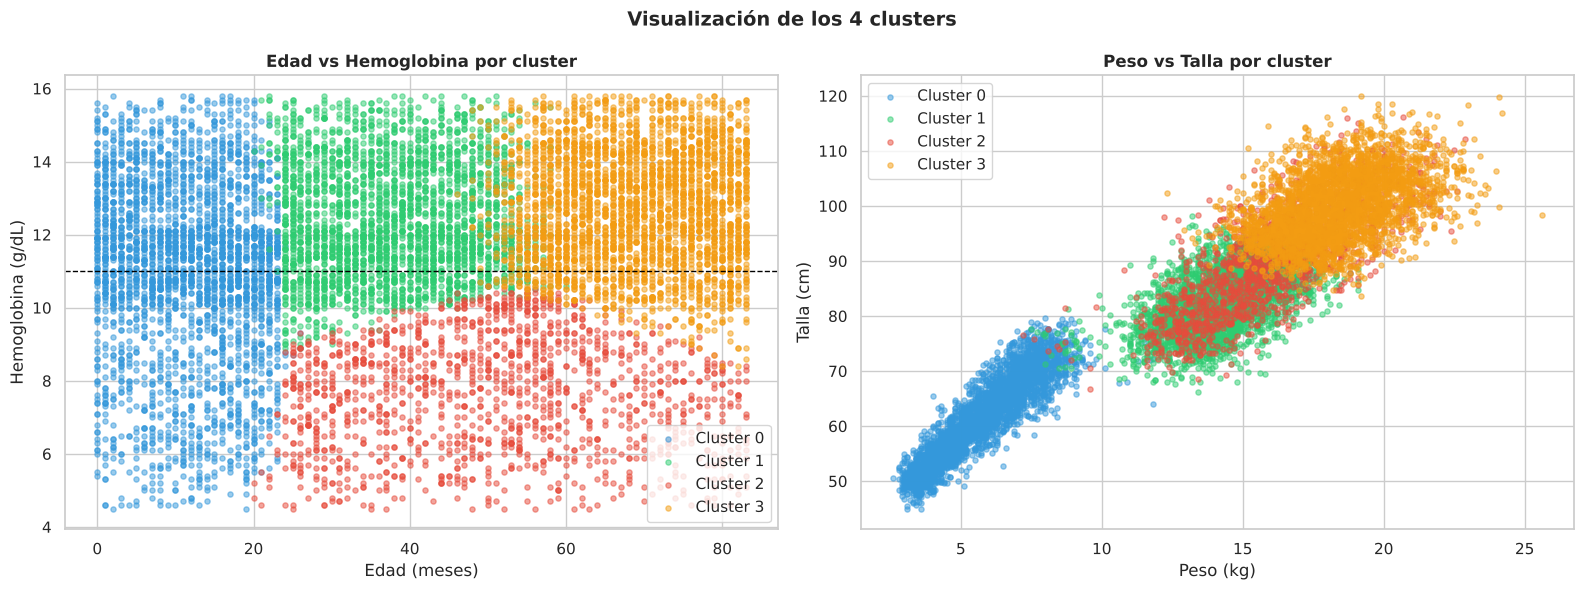

In [ ]:
COLORES = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for c in range(K_OPTIMO):
    m = df['Cluster'] == c
    axes[0].scatter(df[m]['Edad_Meses'], df[m]['Hemoglobina_g_dL'],
                    c=COLORES[c], label=f'Cluster {c}', alpha=0.5, s=14)
    axes[1].scatter(df[m]['Peso_kg'], df[m]['Talla_cm'],
                    c=COLORES[c], label=f'Cluster {c}', alpha=0.5, s=14)

axes[0].axhline(11, color='black', linestyle='--', linewidth=1)
axes[0].set_title('Edad vs Hemoglobina por cluster', fontweight='bold')
axes[0].set_xlabel('Edad (meses)'); axes[0].set_ylabel('Hemoglobina (g/dL)'); axes[0].legend()

axes[1].set_title('Peso vs Talla por cluster', fontweight='bold')
axes[1].set_xlabel('Peso (kg)'); axes[1].set_ylabel('Talla (cm)'); axes[1].legend()

plt.suptitle('Visualización de los 4 clusters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Qué significa:** cada color es un cluster. En *Edad vs Hemoglobina* los grupos se ordenan por edad de izquierda a derecha: **azul (0)** hasta unos 22 meses, **verde (1)** de unos 23 a 52 meses y **naranja (3)** desde unos 52 meses. El **rojo (2)** es distinto: aparece en la parte baja del gráfico (hemoglobina menor a unos 10 g/dL) en niños de más de 22 meses, sin importar la edad exacta. En *Peso vs Talla* el cluster 0 queda bien separado, mientras que los clusters 1, 2 y 3 se solapan en parte porque se diferencian más por edad y hemoglobina que por tamaño.

**¿En qué se diferencia cada cluster en cada variable?**

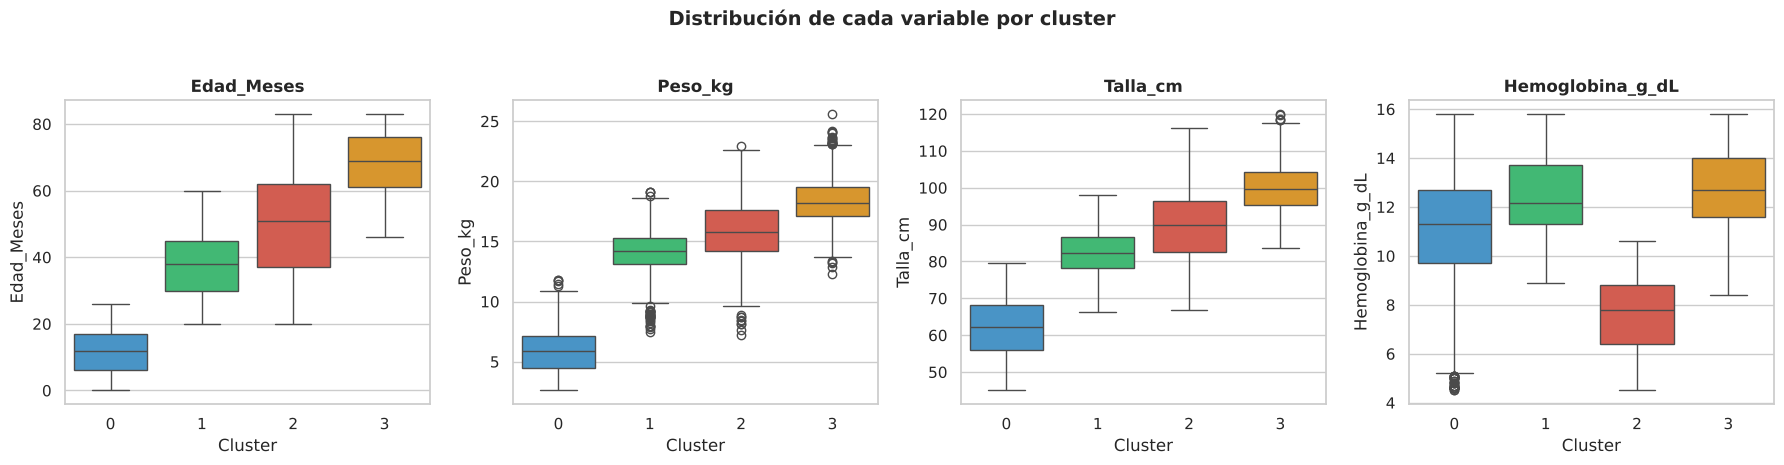

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, features):
    sns.boxplot(x='Cluster', y=col, data=df, palette=COLORES, ax=ax)
    ax.set_title(col, fontweight='bold')
plt.suptitle('Distribución de cada variable por cluster', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

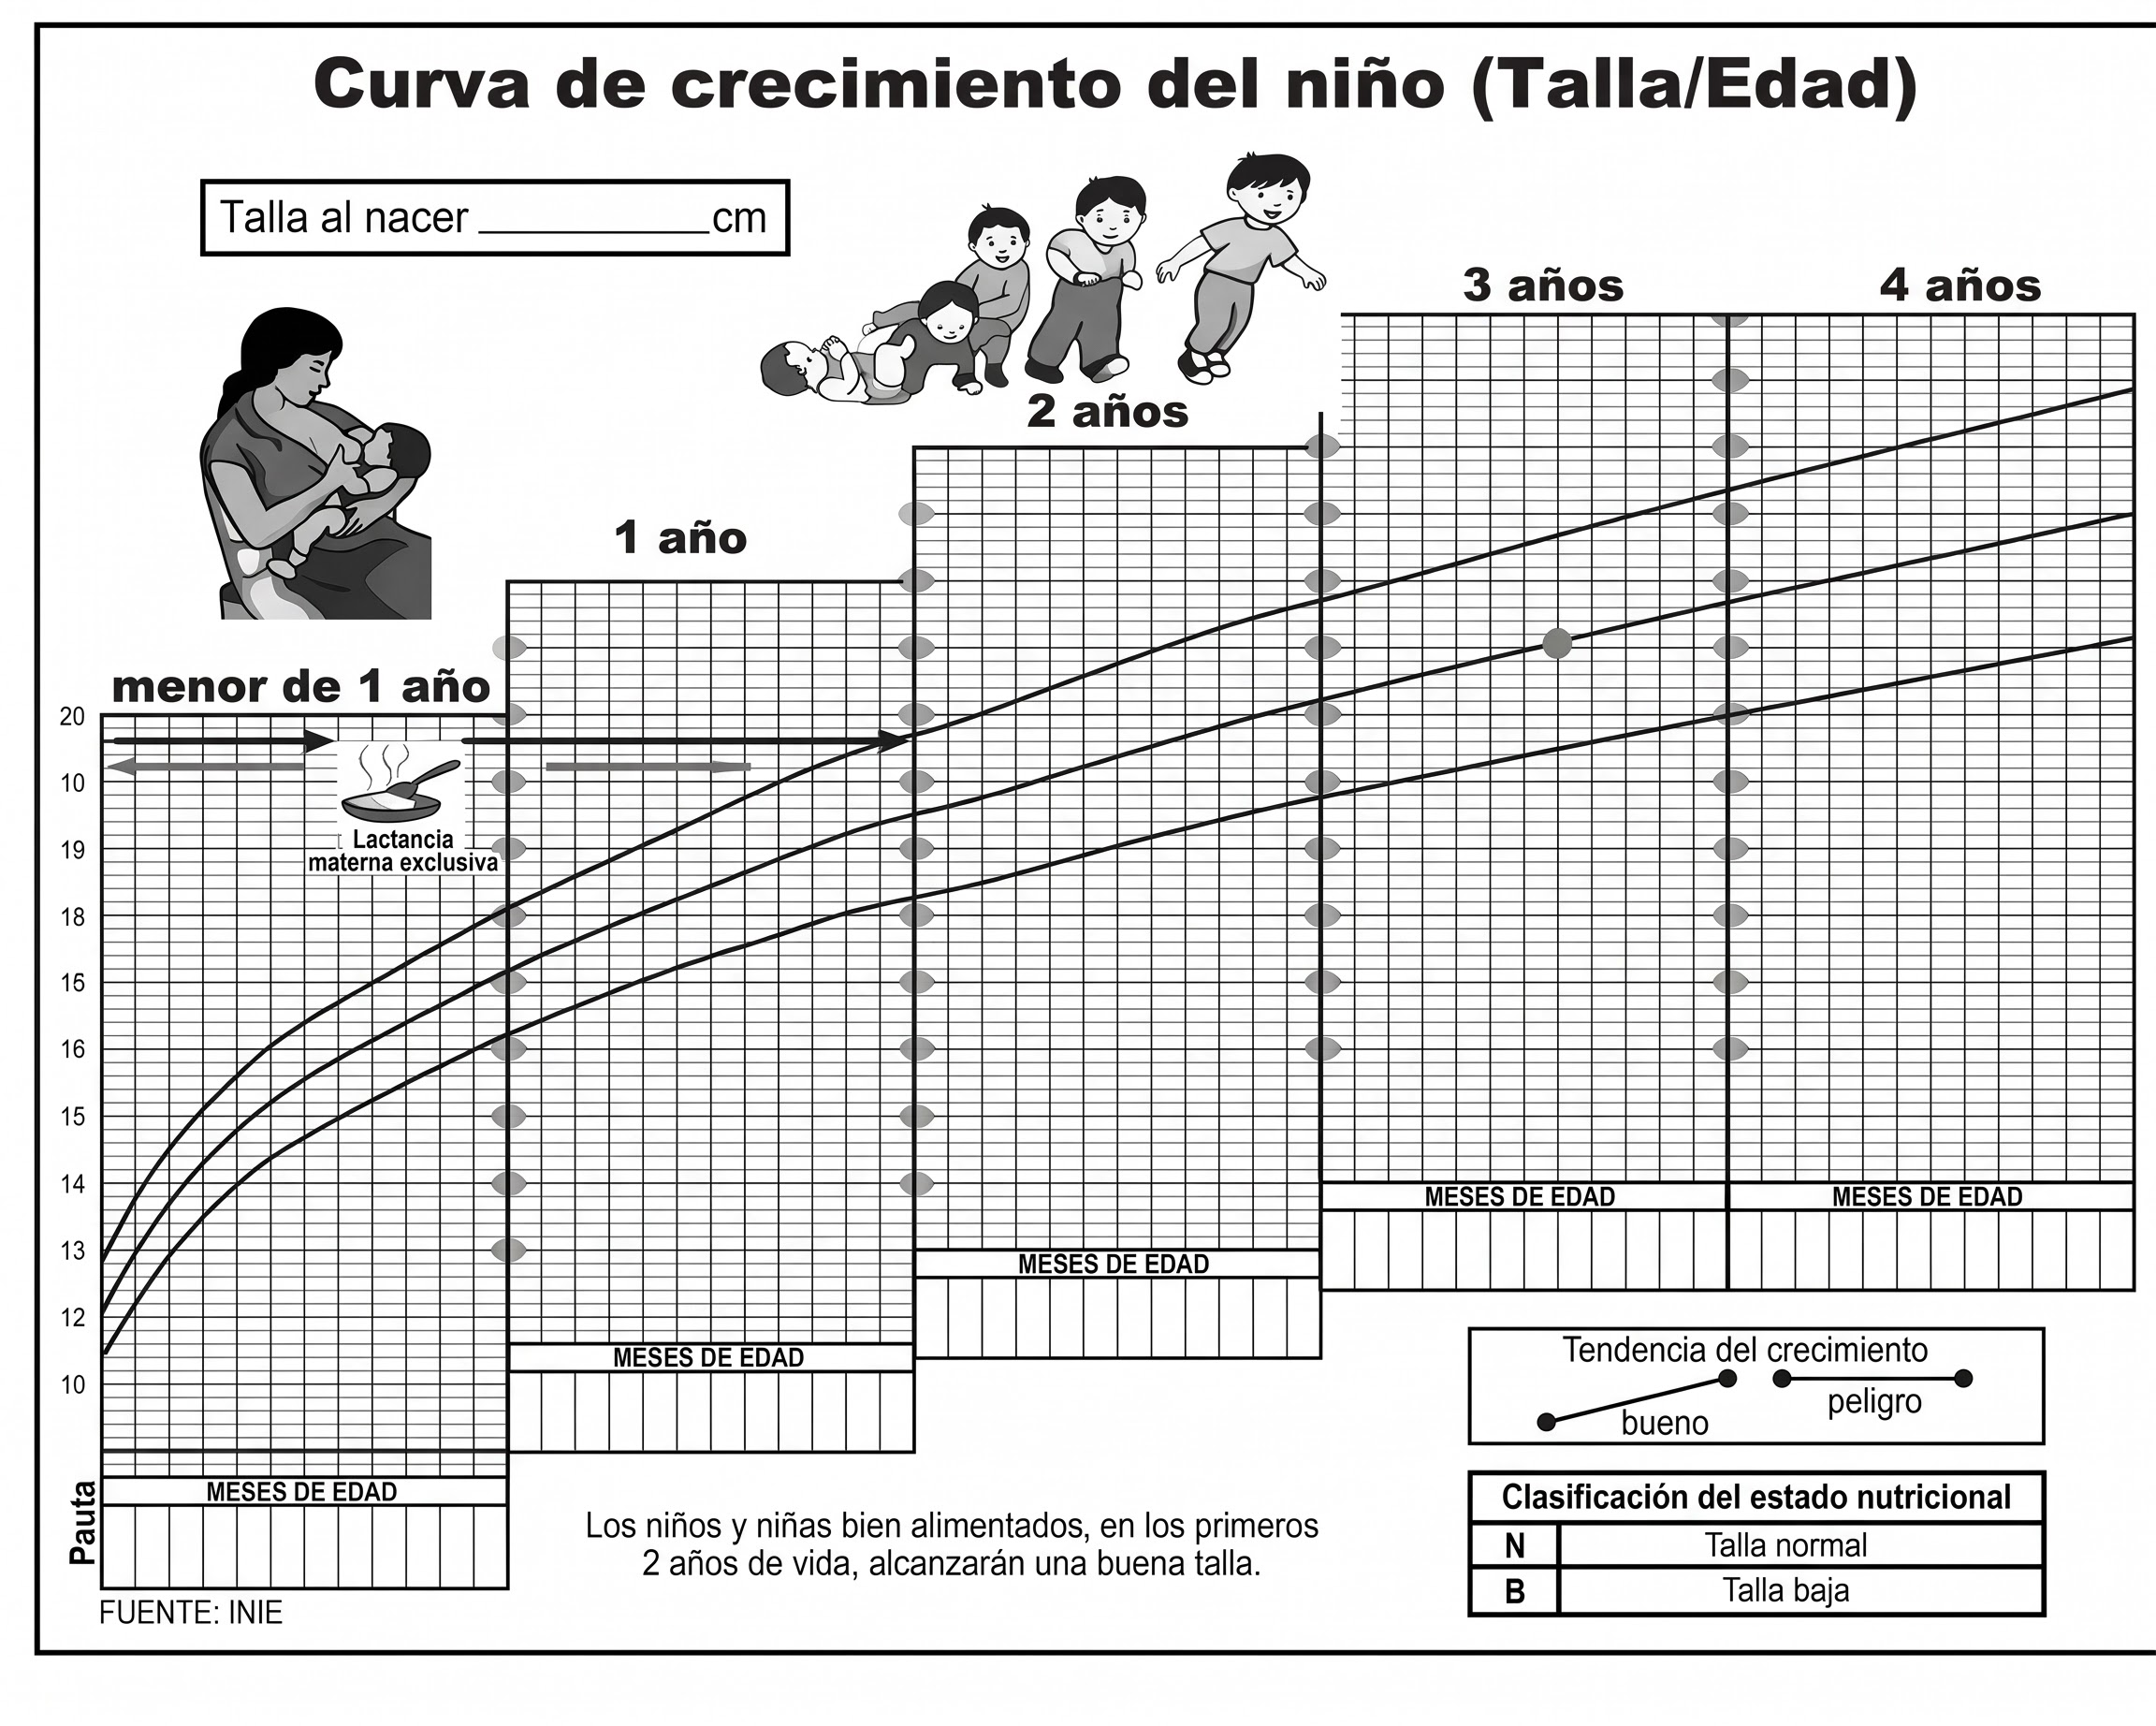**Qué significa:** los boxplots confirman las diferencias. Edad, peso y talla aumentan del cluster 0 al 3, salvo el cluster 2, que queda en un punto intermedio de edad, peso y talla. La hemoglobina del **cluster 2 es claramente la más baja** de todos, mientras los clusters 1 y 3 tienen hemoglobina más alta y el cluster 0 queda en un nivel intermedio-bajo.

---
## 8. Perfilado de los clusters
**¿Cuál es el perfil promedio de cada grupo?**

         N_niños  Edad_Meses  Peso_kg  Talla_cm  Hemoglobina_g_dL
Cluster                                                          
0           2967       11.54     5.85     62.11             10.97
1           2938       37.99    14.18     82.39             12.42
2           1441       50.65    15.95     89.76              7.66
3           3154       68.73    18.34     99.97             12.74


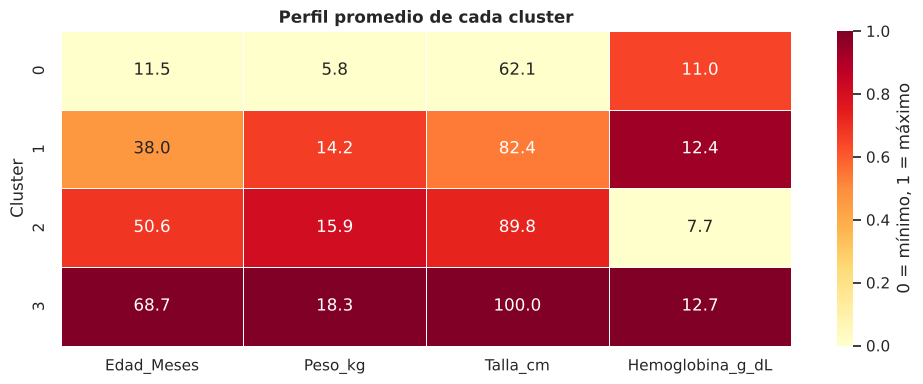

In [ ]:
perfil = df.groupby('Cluster')[features].mean().round(2)
perfil.insert(0, 'N_niños', df['Cluster'].value_counts().sort_index())
print(perfil.to_string())

# Heatmap normalizado para comparar visualmente
perfil_vars = perfil[features]
norm = (perfil_vars - perfil_vars.min()) / (perfil_vars.max() - perfil_vars.min())

plt.figure(figsize=(10, 4))
sns.heatmap(norm, annot=perfil_vars, fmt='.1f', cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': '0 = mínimo, 1 = máximo'})
plt.title('Perfil promedio de cada cluster', fontweight='bold')
plt.tight_layout()
plt.show()

**Qué significa:**
- **Cluster 0:** niños menores de 2 años (promedio ~11 meses), 5.9 kg, 62 cm, hemoglobina 10.97 (apenas bajo el límite de 11).
- **Cluster 1:** niños de ~38 meses (3 años), 14.2 kg, hemoglobina **12.4** (normal).
- **Cluster 2:** niños de ~51 meses, 16 kg, hemoglobina **7.66**, muy por debajo de lo normal.
- **Cluster 3:** escolares de ~69 meses (casi 6 años), 18.3 kg, hemoglobina **12.7** (la más alta).

---
## 9. ¿Los grupos tienen sentido clínico?
**K-Means no vio la columna `Grado_Anemia`. ¿Cómo se reparte la anemia dentro de cada cluster?**

Porcentaje de cada grado de anemia dentro de cada cluster:
Grado_Anemia  Sin anemia  Leve  Moderada  Severa  Con anemia (%)
Cluster                                                         
0                   34.6  34.9      18.7    11.8            65.4
1                   59.6  34.2       6.2     0.0            40.4
2                    0.0   4.9      48.6    46.5           100.0
3                   71.5  23.5       5.0     0.0            28.5


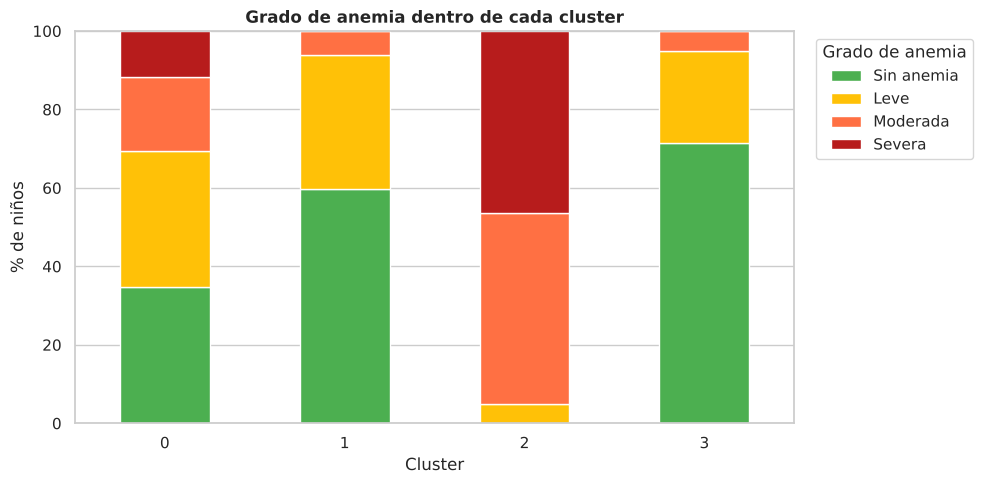

In [ ]:
# K-Means NO usó la columna Grado_Anemia. Ahora la usamos para comprobar si los grupos tienen sentido clínico.
orden_grado = ['Sin anemia', 'Leve', 'Moderada', 'Severa']

tabla = pd.crosstab(df['Cluster'], df['Grado_Anemia'], normalize='index')[orden_grado] * 100
tabla['Con anemia (%)'] = 100 - tabla['Sin anemia']
print("Porcentaje de cada grado de anemia dentro de cada cluster:")
print(tabla.round(1).to_string())

tabla[orden_grado].plot(kind='bar', stacked=True, figsize=(10, 5),
                        color=['#4CAF50', '#FFC107', '#FF7043', '#B71C1C'])
plt.title('Grado de anemia dentro de cada cluster', fontweight='bold')
plt.xlabel('Cluster'); plt.ylabel('% de niños')
plt.xticks(rotation=0)
plt.legend(title='Grado de anemia', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Qué significa:** este es el resultado más importante del análisis.
- **Cluster 2:** el **100% tiene anemia** y casi todos son de grado **moderado (48.6%) o severo (46.5%)**. K-Means encontró por sí solo al grupo más grave.
- **Cluster 0 (lactantes):** **65.4%** tiene anemia y es el único otro grupo con casos severos (11.8%). Es el grupo de edad más vulnerable.
- **Clusters 1 y 3:** tienen menos anemia (40.4% y 28.5%), casi toda de grado leve, y **ningún caso severo**.

Es decir, el algoritmo separó los niveles de riesgo sin conocer el diagnóstico.

**¿Cómo son los grupos en otras características (edad por grupo etario, área, suplemento de hierro, educación de la madre)?**

In [ ]:
# Otras características de los niños en cada cluster (variables que K-Means no usó)
print("Grupo etario por cluster (cantidad de niños):")
print(pd.crosstab(df['Cluster'], df['Grupo_Etario']).to_string())
print()

otras = pd.DataFrame({
    '% Área rural'           : df.groupby('Cluster')['Área'].apply(lambda s: (s == 'Rural').mean() * 100),
    '% Toma suplemento hierro': df.groupby('Cluster')['Consume_Suplemento_Hierro'].apply(lambda s: (s == 'Sí').mean() * 100),
    '% Madre sin educación'  : df.groupby('Cluster')['Nivel_Educativo_Madre'].apply(lambda s: (s == 'Ninguna').mean() * 100),
}).round(1)
print(otras.to_string())

Grupo etario por cluster (cantidad de niños):
Grupo_Etario  0-5 meses (lactante < 6m)  12-23 meses (lactante mayor)  24-59 meses (preescolar)  6-11 meses (lactante menor)  60-83 meses (escolar 5-7 años)
Cluster                                                                                                                                                     
0                                   731                          1512                         8                          716                               0
1                                     0                            32                      2905                            0                               1
2                                     0                            12                      1023                            0                             406
3                                     0                             0                       583                            0                            2571

         % 

**Qué significa:** el cluster 0 está formado por niños de 0 a 23 meses, el cluster 1 casi solo por preescolares (24-59 meses) y el cluster 3 sobre todo por escolares de 60 a 83 meses. El cluster 2 mezcla preescolares (1,023) y escolares (406): lo que los une es la hemoglobina baja, no la edad. En área rural, suplemento de hierro y educación de la madre los porcentajes son parecidos entre los clusters (por ejemplo, 30% a 35% rural), así que **esas variables no son las que diferencian a los grupos**. Cabe notar que el cluster 2 tiene el mayor porcentaje con suplemento (42.3%); no significa que el hierro cause anemia, sino que probablemente se le da a niños que ya tienen anemia, y el estudio no permite probar causalidad.

---
## 10. Nombres de los clusters
**¿Qué nombre le damos a cada grupo?**

In [ ]:
nombres = {
    0: 'Menores de 2 años (lactantes)',
    1: 'Preescolares (alrededor de 3 años)',
    2: 'Anemia moderada-severa (alrededor de 4 años)',
    3: 'Escolares (5-7 años)',
}
df['Perfil'] = df['Cluster'].map(nombres)

resumen = df.groupby('Perfil').agg(
    Niños=('ID_Registro', 'count'),
    Edad_prom=('Edad_Meses', 'mean'),
    Hb_prom=('Hemoglobina_g_dL', 'mean'),
    Con_anemia_pct=('Grado_Anemia', lambda s: (s != 'Sin anemia').mean() * 100)
).round(1)
resumen

,Niños,Edad_prom,Hb_prom,Con_anemia_pct
Perfil,,,,
Anemia moderada-severa (alrededor de 4 años),1441,50.7,7.7,100.0
Escolares (5-7 años),3154,68.7,12.7,28.5
Menores de 2 años (lactantes),2967,11.5,11.0,65.4
Preescolares (alrededor de 3 años),2938,38.0,12.4,40.4


**Qué significa:** con base en el perfil, cada grupo recibe un nombre que describe a los niños:

| Cluster | Perfil | Lectura de salud pública |
|---|---|---|
| 0 | **Menores de 2 años (lactantes)** | Grupo vulnerable: 65% con anemia, incluye casos severos. Prioridad para suplementación y control temprano. |
| 1 | **Preescolares (≈3 años)** | Riesgo medio: 40% con anemia, casi toda leve. Seguimiento y alimentación rica en hierro. |
| 2 | **Anemia moderada-severa (≈4 años)** | Grupo crítico: 100% con anemia, hemoglobina promedio 7.7. Requiere atención médica y tratamiento inmediato. |
| 3 | **Escolares (5-7 años)** | Menor riesgo: 28% con anemia, ninguna severa. Control de rutina. |

---
## 11. Evaluación del modelo
**¿Qué tan bueno es el modelo?**

In [ ]:
# ==============================================================================
# 🧠 COMENTARIO DEL ANALISTA: EL VEREDICTO FINAL DE LAS MÉTRICAS
# ==============================================================================
# Terminamos con un Silhouette Score de aproximadamente 0.39. En proyectos
# biológicos o de salud pública como este, un valor entre 0.25 y 0.50 es
# bastante común y se considera un resultado sólido.
#
# ¿Por qué no sacamos un 0.80 o 0.90? Porque los niños no crecen en saltos
# discretos; un bebé de 23 meses es casi idéntico físicamente a uno de 24 meses.
# Hay un solapamiento natural. Lo verdaderamente valioso aquí no es alcanzar la
# métrica perfecta, sino el hecho de que el modelo haya logrado descubrir por
# sí mismo un segmento altamente concentrado con "anemia severa/moderada"
# sin que le hayamos dado esa etiqueta. ¡Ese es el poder del Machine Learning!
# ==============================================================================

labels_final = df['Cluster'].values
sil_final = silhouette_score(X_scaled, labels_final, sample_size=5000, random_state=42)

print("MÉTRICAS DEL MODELO K-MEANS")
print("=" * 40)
print(f"  Número de clusters : {K_OPTIMO}")
print(f"  WCSS (inercia)     : {kmeans.inertia_:,.2f}")
print(f"  Silhouette Score   : {sil_final:.4f}")
print(f"  Iteraciones usadas : {kmeans.n_iter_}")

if sil_final > 0.7:
    interp = "Excelente: clusters muy bien definidos"
elif sil_final > 0.5:
    interp = "Bueno: clusters razonablemente bien definidos"
elif sil_final > 0.25:
    interp = "Aceptable: hay algo de superposición entre clusters"
else:
    interp = "Débil: los clusters se solapan mucho"
print(f"  Interpretación     : {interp}")

MÉTRICAS DEL MODELO K-MEANS
  Número de clusters : 4
  WCSS (inercia)     : 10,486.57
  Silhouette Score   : 0.3926
  Iteraciones usadas : 12
  Interpretación     : Aceptable: hay algo de superposición entre clusters


**Qué significa:** el Silhouette de **0.39** indica una calidad **aceptable**: los grupos existen y tienen sentido, pero se solapan un poco en sus bordes, algo normal porque los niños crecen de forma continua y no hay fronteras exactas entre edades. El WCSS (10,486) es la dispersión total dentro de los grupos; sirve para comparar con otros valores de K, no tiene una escala "buena" por sí solo.

---
## 12. Resumen final

In [ ]:
print("RESUMEN — H4_1 K-Means: Anemia Infantil en Bolivia (0 a 7 años)")
print("=" * 60)
print(f"  Registros usados : {len(df):,} niños")
print(f"  Variables usadas : {', '.join(features)}")
print(f"  Algoritmo        : K-Means (scikit-learn), K = {K_OPTIMO}")
print(f"  Silhouette Score : {sil_final:.4f}")
print()
for c in range(K_OPTIMO):
    sub = df[df['Cluster'] == c]
    anemia = (sub['Grado_Anemia'] != 'Sin anemia').mean() * 100
    print(f"  Cluster {c} | {nombres[c]:<46} | {len(sub):5,d} niños | anemia {anemia:5.1f}%")

RESUMEN — H4_1 K-Means: Anemia Infantil en Bolivia (0 a 7 años)
  Registros usados : 10,500 niños
  Variables usadas : Edad_Meses, Peso_kg, Talla_cm, Hemoglobina_g_dL
  Algoritmo        : K-Means (scikit-learn), K = 4
  Silhouette Score : 0.3926

  Cluster 0 | Menores de 2 años (lactantes)                  | 2,967 niños | anemia  65.4%
  Cluster 1 | Preescolares (alrededor de 3 años)             | 2,938 niños | anemia  40.4%
  Cluster 2 | Anemia moderada-severa (alrededor de 4 años)   | 1,441 niños | anemia 100.0%
  Cluster 3 | Escolares (5-7 años)                           | 3,154 niños | anemia  28.5%


**Qué significa:** resumen de todo el análisis en una sola salida: 10,500 niños, 4 variables, K = 4 y un Silhouette de 0.39, con el perfil y el porcentaje de anemia de cada grupo.

---
## Conclusiones

1. **K-Means separó a los niños en 4 grupos** con sentido clínico, usando solo edad, peso, talla y hemoglobina, sin conocer el diagnóstico.
2. **El grupo más crítico es el cluster 2** (13.7% de los niños, 1,441): todos con anemia, casi todos moderada o severa. Son los que requieren atención prioritaria.
3. **Los lactantes (cluster 0) son el segundo grupo de riesgo**: 65% con anemia y casos severos, por lo que conviene reforzar el tamizaje y el suplemento de hierro antes de los 2 años.
4. **Los escolares de 5 a 7 años (cluster 3) son el grupo con menor anemia** (28.5%) y sin casos severos.
5. **K = 4** se eligió por el método del codo y el Silhouette (0.39, calidad aceptable).

## Limitaciones

- Los datos del archivo son **simulados** (calibrados con estadísticas de ENDSA), por lo que los resultados sirven para el ejercicio académico y no para sacar conclusiones sobre la población real.
- Como incluimos la hemoglobina, el cluster 2 queda definido en gran parte por esa variable, que es justamente lo que define la anemia. Es esperable y no es un error, pero conviene tenerlo en cuenta.
- K-Means asume grupos redondeados y es sensible a valores extremos; se podría comparar con DBSCAN o clustering jerárquico en una siguiente práctica.

Aviso: No se encontró el archivo Excel en la carpeta. Generando datos simulados para testeo...
Calculando clusters con K-Means (K=4)...


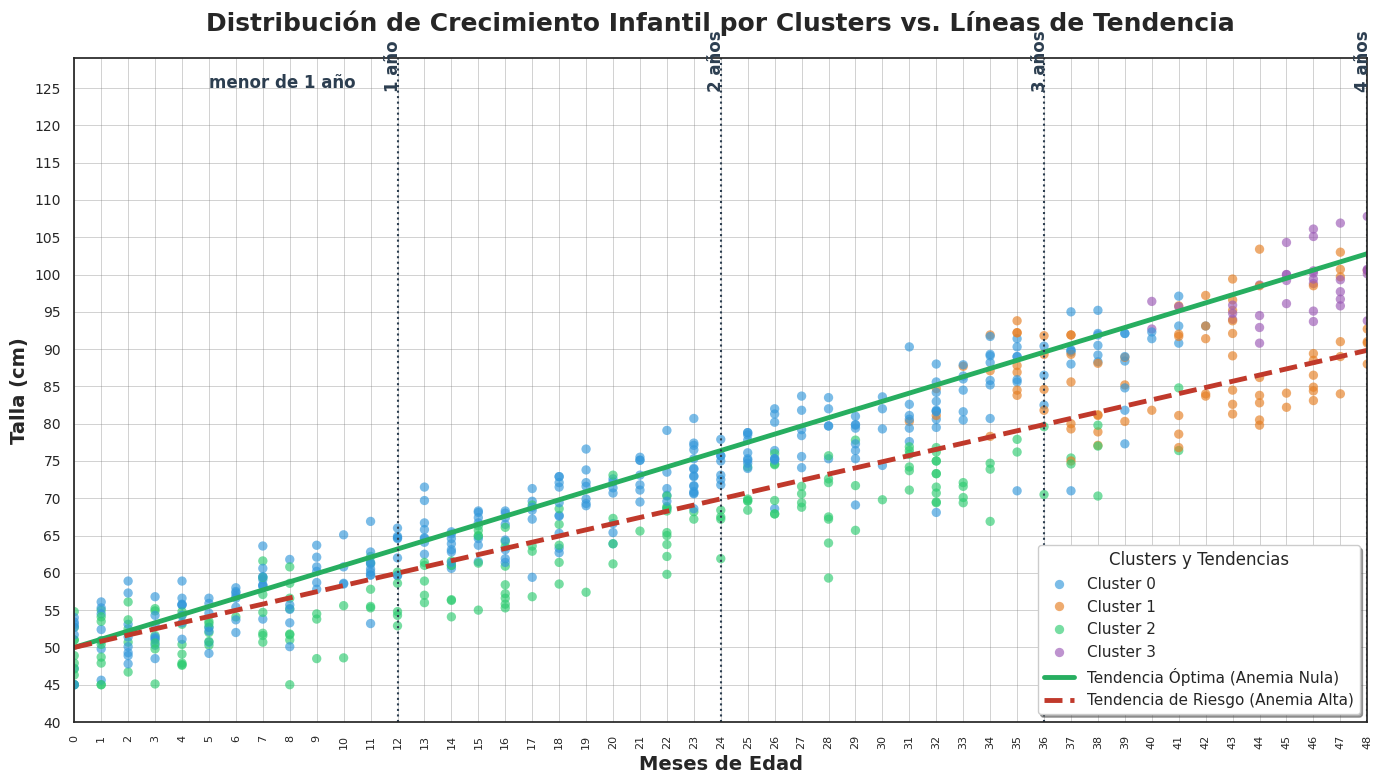

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings

warnings.filterwarnings('ignore')

# 1. Cargar el archivo de Excel (verifica ambos nombres posibles del archivo)
archivos_posibles = ['anemia_infantil_datos.xlsx', 'anemia infantil datos.xlsx']
df_cargado = False

for ruta in archivos_posibles:
    try:
        # Se agrega header=3 para omitir las líneas de título del archivo de Excel
        df = pd.read_excel(ruta, header=3)
        print(f"¡Datos cargados correctamente desde: '{ruta}'! ({df.shape[0]:,} registros)")
        df_cargado = True
        break
    except FileNotFoundError:
        continue

# Si no se encuentra el archivo en el directorio, genera datos simulados realistas para el testeo
if not df_cargado:
    print("Aviso: No se encontró el archivo Excel en la carpeta. Generando datos simulados para testeo...")
    np.random.seed(42)
    n = 1000
    edades = np.random.randint(0, 84, n)
    # Simulamos niños con crecimiento normal y niños con retraso/anemia
    es_anemico = np.random.choice([0, 1], size=n, p=[0.6, 0.4])
    tallas = np.where(
        es_anemico == 0,
        50 + 1.05 * edades + np.random.normal(0, 3.2, n),
        48 + 0.82 * edades + np.random.normal(0, 3.5, n)
    )
    pesos = np.where(
        es_anemico == 0,
        3.5 + 0.25 * edades + np.random.normal(0, 1.2, n),
        3.0 + 0.19 * edades + np.random.normal(0, 1.2, n)
    )
    hb = np.where(
        es_anemico == 0,
        np.random.normal(12.6, 1.0, n),
        np.random.normal(9.2, 1.3, n)
    )
    df = pd.DataFrame({
        'Edad_Meses': edades,
        'Peso_kg': np.clip(pesos, 2.5, 26.0).round(1),
        'Talla_cm': np.clip(tallas, 45.0, 125.0).round(1),
        'Hemoglobina_g_dL': np.clip(hb, 4.5, 16.0).round(1)
    })

# 2. Verificar o calcular los Clusters con K-Means
col_cluster = None
for col in ['Cluster_Nombre', 'Cluster', 'cluster', 'Grupo']:
    if col in df.columns:
        col_cluster = col
        break

if col_cluster is None:
    print("Calculando clusters con K-Means (K=4)...")
    vars_num = ['Edad_Meses', 'Peso_kg', 'Talla_cm', 'Hemoglobina_g_dL']
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df[vars_num])

    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
    df['Cluster'] = kmeans.fit_predict(X_scaled)
    df['Cluster_Label'] = 'Cluster ' + df['Cluster'].astype(str)
    col_cluster = 'Cluster_Label'
else:
    # Nos aseguramos de que tenga formato categórico/texto para que la leyenda sea clara
    df['Cluster_Label'] = 'Cluster ' + df[col_cluster].astype(str)
    col_cluster = 'Cluster_Label'

# Ordenamos los clusters para la leyenda
orden_clusters = sorted(df[col_cluster].unique())

# Paleta de colores vivos (consistente con los colores de tu notebook)
paleta_clusters = ['#3498db', '#e67e22', '#2ecc71', '#9b59b6', '#e74c3c'][:len(orden_clusters)]

# 3. Configuración visual del gráfico
sns.set_theme(style="white")
plt.figure(figsize=(14, 8))

# 4. Graficar los datos reales coloreados por su Cluster
sns.scatterplot(
    data=df,
    x='Edad_Meses',
    y='Talla_cm',
    hue=col_cluster,
    hue_order=orden_clusters,
    palette=paleta_clusters,
    alpha=0.65,
    s=45,
    edgecolor='none'
)

# 5. Añadir las líneas de crecimiento lineal fijas (0 a 48 meses)
meses_x = np.arange(0, 49)

# LÍNEA 1: Tendencia "Anemia Nula" (Crecimiento Saludable)
talla_anemia_nula = 50 + (1.10 * meses_x)
plt.plot(
    meses_x, talla_anemia_nula,
    color='#27ae60', linewidth=3.5, linestyle='-',
    label='Tendencia Óptima (Anemia Nula)'
)

# LÍNEA 2: Tendencia "Anemia Alta" (Retraso de crecimiento)
talla_anemia_alta = 50 + (0.83 * meses_x)
plt.plot(
    meses_x, talla_anemia_alta,
    color='#c0392b', linewidth=3.5, linestyle='--',
    label='Tendencia de Riesgo (Anemia Alta)'
)

# 6. Personalización del gráfico (Formato cartilla INIE)
plt.title('Distribución de Crecimiento Infantil por Clusters vs. Líneas de Tendencia', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Meses de Edad', fontsize=14, fontweight='bold')
plt.ylabel('Talla (cm)', fontsize=14, fontweight='bold')

plt.xlim(0, 48)
plt.xticks(range(0, 49, 1), rotation=90, fontsize=8)
plt.yticks(range(40, 130, 5), fontsize=10)
plt.grid(True, which='both', linestyle='-', linewidth=0.5, color='gray', alpha=0.5)

# Segmentación de bloques anuales
años_meses = {12: '1 año', 24: '2 años', 36: '3 años', 48: '4 años'}
for mes, etiqueta in años_meses.items():
    plt.axvline(x=mes, color='#2c3e50', linestyle=':', linewidth=1.5)
    plt.text(mes - 0.5, 125, etiqueta, rotation=90, color='#2c3e50', fontweight='bold', fontsize=12)

plt.text(5, 125, 'menor de 1 año', color='#2c3e50', fontweight='bold', fontsize=12)

# 7. Mostrar el gráfico con leyenda unificada
plt.legend(
    title='Clusters y Tendencias',
    loc='lower right',
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    shadow=True
)
plt.tight_layout()
plt.show()

 * Los puntos (Nube de dispersión): Cada punto individual representa a un paciente de tu base de datos clínica. Su ubicación cruza la edad en meses (eje horizontal) con la talla en centímetros (eje vertical). La aglomeración de estos puntos te permite visualizar si la población infantil estudiada tiende hacia un desarrollo sano o si presenta una concentración anómala de talla baja.
 * La línea verde (Tendencia Óptima / Anemia Nula): Traza el crecimiento lineal continuo de un niño sano. Parte de una talla base estándar al nacer (50 cm) y mantiene una pendiente ascendente constante (1.10 cm por mes) hasta llegar a los ~103 cm a los 4 años. Equivale a la clasificación de crecimiento "bueno" y talla "normal" (N) en la cartilla física del INIE.
 * La línea roja (Tendencia de Riesgo / Anemia Alta): Simula el estancamiento del desarrollo físico provocado por una deficiencia severa. Inicia en los mismos 50 cm, pero su inclinación es considerablemente más plana (0.83 cm por mes), alcanzando apenas unos ~90 cm a los 4 años. Representa la zona de "peligro" o "talla baja" (B) de la cartilla original, donde la curva de crecimiento se ralentiza o se vuelve horizontal.
